# Wilson–Cowan E–I field in 2D: patterns along $y$ from an input uniform along $y$

Report Sec. 10, same structure as `v1_2d.ipynb`. For this model $\mathrm{Re}\,c_\theta>0$ for $71^\circ\lesssim\theta\lesssim146^\circ$, so the theory predicts that the locked patterns form and then lose stability to other shell waves. Each batch takes about 1 minute.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from mcn_project import plotting
from mcn_project.analysis import shell_amplitudes
from mcn_project.linear import critical_wavenumber, find_onset
from mcn_project.normal_form import cubic_coefficients, pair_forcing_coefficient
from mcn_project.shell import flicker_states, locked_pair, shell_waves
from mcn_project.simulate import Forcing, Wave, simulate, simulate_seeds

plt.rcParams["figure.dpi"] = 80

In [2]:
# ---- parameters ----
from mcn_project import presets
PRESET, KAPPA_RANGE = presets.wilson_cowan, (4.0, 12.0)   # kappa = a_EE; model time units
MU = -1.0                                                  # below onset: kappa = kappa_c + MU * EPS**2
N, DT, SAVE_EVERY = 32, 0.1, 20
NOISE = 0.1                                                # random initial field: std NOISE * EPS per point
# route 1 (x-traveling input on an oblique shell)
EPS, STRENGTH, T_ROUTE1, SEEDS = 0.1, 3.0, 9_000.0, [0, 1, 2]
# route 2 (uniform flicker on the axial shell)
EPS_FLICKER, FLICKER_PEAK, T_ROUTE2, FLICKER_SEEDS = 0.1, 1.0, 6_000.0, [0, 1, 2, 3]

In [3]:
def run_route1(r2, pair, K):
    """x-traveling input cos(K.x + 2 w0 t) on a torus whose critical shell is |k|^2 = r2."""
    L = np.sqrt(r2) * 2 * np.pi / critical_wavenumber(PRESET(), KAPPA_RANGE)
    model = PRESET(length=L)
    onset = find_onset(model, 2, KAPPA_RANGE)
    a = MU * cubic_coefficients(model, onset).alpha
    eta_unit = pair_forcing_coefficient(model, onset, 2 * np.pi * np.hypot(*K) / L, model.drive / 2, "2w0")
    peak = STRENGTH * abs(a) / abs(eta_unit)
    pred = locked_pair(model, onset, a, r2, pair, K, peak * model.drive / 2)
    forcing = Forcing((Wave(peak * EPS**2, K, -2 * onset.omega0),))
    runs = simulate_seeds(model, onset.kappa + MU * EPS**2, forcing, SEEDS, dim=2, n=N, dt=DT,
                          t_end=T_ROUTE1, save_every=SAVE_EVERY, noise=NOISE * EPS)
    amps = [shell_amplitudes(r, onset, shell_waves(r2)) for r in runs]
    print(f"L = {L:.3f}, critical shell |k|^2 = {onset.k0**2:.0f}, input peak = {peak:.3f} eps^2")
    print(f"prediction: eps|A| = {EPS * np.sqrt(pred['rho']):.5f} for {pair}; "
          f"largest shell eigenvalues {np.round(pred['eigenvalues'], 4)} (0 = translation along y)")
    return dict(model=model, onset=onset, forcing=forcing, pred=pred, runs=runs, amps=amps)


def summarize(res, pair):
    rows, others = [], []
    for run, amps in zip(res["runs"], res["amps"]):
        late = run.t > 0.8 * run.t[-1]
        rows.append([abs(amps[k][late]).mean() for k in pair])
        others.append(max(abs(v[late]).mean() for k, v in amps.items() if k not in pair))
    rows = np.array(rows)
    for seed, row, other in zip(SEEDS, rows, others):
        print(f"  seed {seed}: eps|A| = {row[0]:.5f}, {row[1]:.5f}; largest other wave {other:.1e}")
    print(f"  mean +- sd over seeds: {rows.mean():.5f} +- {rows.std():.5f}; "
          f"theory {EPS * np.sqrt(res['pred']['rho']):.5f}")


def show_route1(res, pair):
    fig, axs = plt.subplots(1, len(SEEDS), figsize=(4 * len(SEEDS), 3), layout="constrained")
    for ax, run, amps, seed in zip(axs, res["runs"], res["amps"], SEEDS):
        plotting.shell_traces(run.t, amps, pair, ax=ax, title=f"seed {seed}")
    fig, axs = plt.subplots(1, len(SEEDS) + 1, figsize=(3.2 * (len(SEEDS) + 1), 3), layout="constrained")
    run = res["runs"][0]
    axs[0].imshow(run.input[-1].T, origin="lower", cmap="RdBu_r", extent=[0, run.x[-1], 0, run.x[-1]])
    axs[0].set(title="input (uniform along y)", xlabel="$x$", ylabel="$y$")
    for ax, run, seed in zip(axs[1:], res["runs"], SEEDS):
        lim = abs(run.u[-1, 0]).max()
        ax.imshow(run.u[-1, 0].T, origin="lower", cmap="RdBu_r", vmin=-lim, vmax=lim,
                  extent=[0, run.x[-1], 0, run.x[-1]])
        ax.set(title=f"E at the end, seed {seed}", xlabel="$x$", ylabel="$y$")
    # short, finely sampled continuation of seed 0: motion along x, standing along y
    run = res["runs"][0]
    period = 2 * np.pi / res["onset"].omega0
    cont = simulate(res["model"], run.kappa, res["forcing"], dim=2, n=N, dt=DT, t_end=2 * period,
                    save_every=max(1, round(period / 8 / DT)), u0=run.u[-1], t_start=run.t[-1])
    plotting.snapshots(cont, cont.t[:4])
    plotting.xt_cut(cont)

## Route 1a: shell $|\boldsymbol k|^2=10$, input $\boldsymbol K=(6,0)$ couples $(3,1)$ and $(3,-1)$

Report Sec. 10.3: the pattern travels along $x$ with the input and is standing along $y$, $\cos(q_1 y)$. Its $y$-position is free (translation), so each random seed picks its own.

In [4]:
PAIR_A = [(3, 1), (3, -1)]
res_a = run_route1(10, PAIR_A, (6, 0))
summarize(res_a, PAIR_A)

L = 61.416, critical shell |k|^2 = 10, input peak = 0.787 eps^2
prediction: eps|A| = 0.02697 for [(3, 1), (3, -1)]; largest shell eigenvalues [0.8385 0.8385 0.8385] (0 = translation along y)
  seed 0: eps|A| = 0.05442, 0.28995; largest other wave 2.9e-01
  seed 1: eps|A| = 0.00422, 0.02463; largest other wave 3.6e-01
  seed 2: eps|A| = 0.00422, 0.02462; largest other wave 3.6e-01
  mean +- sd over seeds: 0.06701 +- 0.10111; theory 0.02697


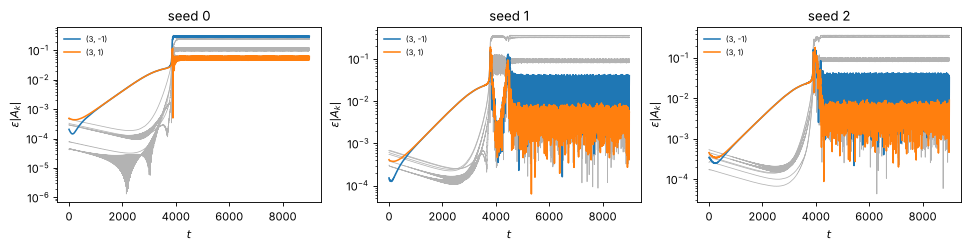

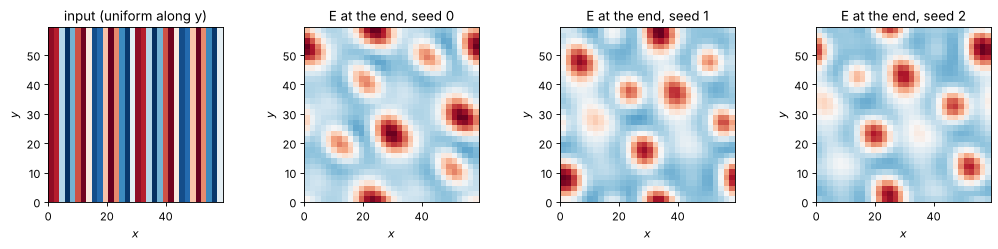

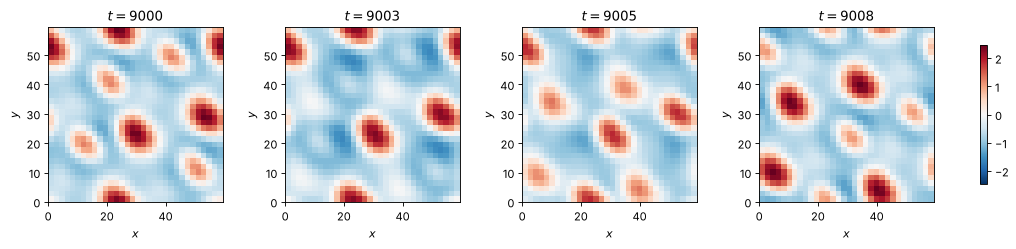

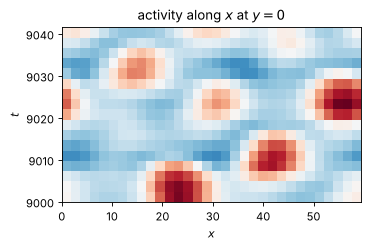

In [5]:
show_route1(res_a, PAIR_A)

## Route 1b: shell $|\boldsymbol k|^2=25$, input $\boldsymbol K=(6,0)$ couples $(3,4)$ and $(3,-4)$

The same input wavevector now produces $y$-mode 4, finer than anything in the input. The shell also contains $(5,0)$, $(0,5)$, $(4,\pm3)$, which must decay.

In [6]:
PAIR_B = [(3, 4), (3, -4)]
res_b = run_route1(25, PAIR_B, (6, 0))
summarize(res_b, PAIR_B)

L = 97.107, critical shell |k|^2 = 25, input peak = 0.748 eps^2
prediction: eps|A| = 0.01521 for [(3, 4), (3, -4)]; largest shell eigenvalues [0.2705 0.2705 0.1571] (0 = translation along y)
  seed 0: eps|A| = 0.05016, 0.05959; largest other wave 6.6e-02
  seed 1: eps|A| = 0.05572, 0.05275; largest other wave 6.2e-02
  seed 2: eps|A| = 0.06450, 0.05423; largest other wave 6.9e-02
  mean +- sd over seeds: 0.05616 +- 0.00471; theory 0.01521


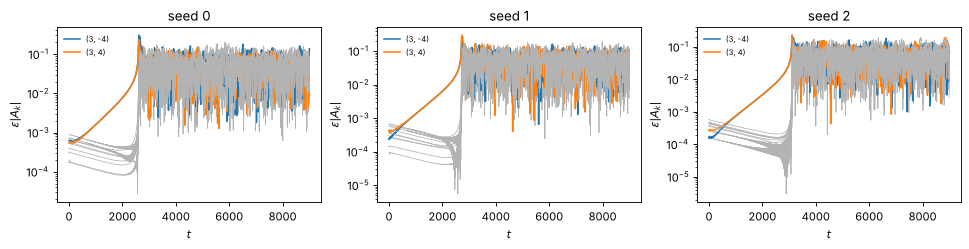

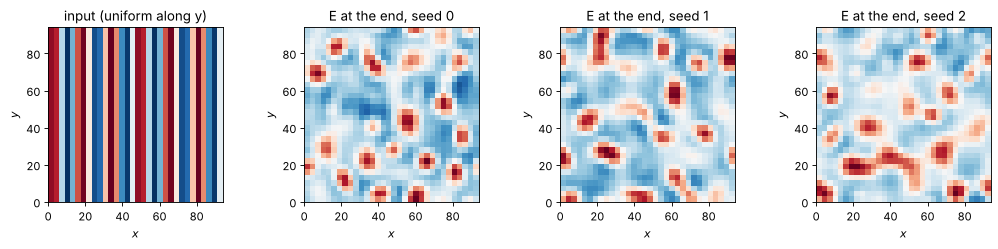

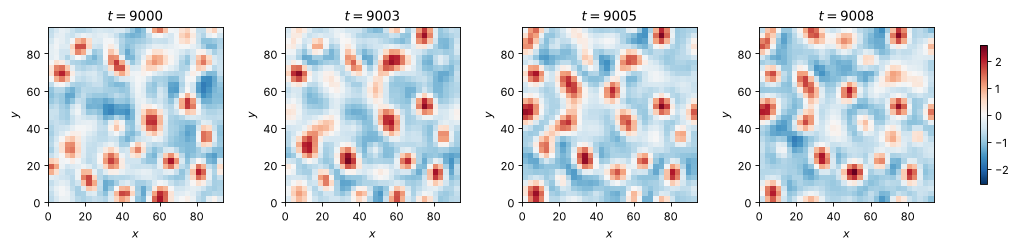

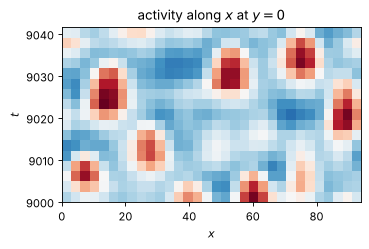

In [7]:
show_route1(res_b, PAIR_B)

## Route 2: uniform flicker on the axial shell

Input uniform in $x$ and $y$ at $2\omega_0$. Each wave couples to its opposite, so stripes along $x$, stripes along $y$, and squares are all possible; random initial states choose. For Wilson–Cowan the theory predicts that stripes and squares are both unstable.

In [8]:
L2 = 3 * 2 * np.pi / critical_wavenumber(PRESET(), KAPPA_RANGE)
model2 = PRESET(length=L2)
onset2 = find_onset(model2, 2, KAPPA_RANGE)
a2 = MU * cubic_coefficients(model2, onset2).alpha
states = flicker_states(model2, onset2, a2, FLICKER_PEAK * model2.drive / 2)
for name, s in states.items():
    print(f"{name}: eps sqrt(rho) = {EPS_FLICKER * np.sqrt(s['rho']):.5f}, "
          f"largest shell eigenvalues {np.round(s['eigenvalues'], 4)}")
forcing2 = Forcing((Wave(FLICKER_PEAK * EPS_FLICKER**2, (), 2 * onset2.omega0),))
runs2 = simulate_seeds(model2, onset2.kappa + MU * EPS_FLICKER**2, forcing2, FLICKER_SEEDS, dim=2, n=N,
                       dt=DT, t_end=T_ROUTE2, save_every=SAVE_EVERY, noise=NOISE * EPS_FLICKER)

stripe: eps sqrt(rho) = 0.02385, largest shell eigenvalues [ 1.8383  1.8383 -0.    ]
square: eps sqrt(rho) = 0.00711, largest shell eigenvalues [0.2364 0.2364 0.051 ]


seed 0: x-waves 0.41834, y-waves 0.41834 -> square


seed 1: x-waves 0.51742, y-waves 0.51742 -> square


seed 2: x-waves 0.49198, y-waves 0.49198 -> square


seed 3: x-waves 0.49459, y-waves 0.49460 -> square
theory for a stripe: sqrt(|A+|^2+|A-|^2) = 0.03373


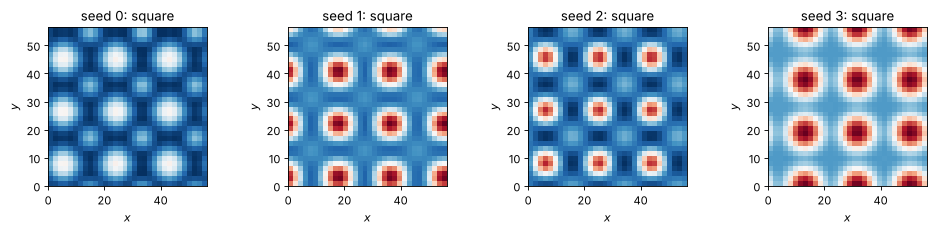

In [9]:
k0 = round(onset2.k0)
fig, axs = plt.subplots(1, len(runs2), figsize=(3 * len(runs2), 2.8), layout="constrained")
for ax, run, seed in zip(axs, runs2, FLICKER_SEEDS):
    amps = shell_amplitudes(run, onset2, shell_waves(k0 * k0))
    x_pair = np.hypot(abs(amps[(k0, 0)]), abs(amps[(-k0, 0)]))
    y_pair = np.hypot(abs(amps[(0, k0)]), abs(amps[(0, -k0)]))
    xe, ye = x_pair[-1], y_pair[-1]
    kind = "square" if min(xe, ye) > 0.5 * max(xe, ye) else ("varies along x" if xe > ye else "varies along y")
    print(f"seed {seed}: x-waves {xe:.5f}, y-waves {ye:.5f} -> {kind}")
    lim = abs(run.u[-1, 0]).max()
    ax.imshow(run.u[-1, 0].T, origin="lower", cmap="RdBu_r", vmin=-lim, vmax=lim,
              extent=[0, run.x[-1], 0, run.x[-1]])
    ax.set(title=f"seed {seed}: {kind}", xlabel="$x$", ylabel="$y$")
print("theory for a stripe: sqrt(|A+|^2+|A-|^2) =", round(np.sqrt(2) * EPS_FLICKER * np.sqrt(states["stripe"]["rho"]), 5))

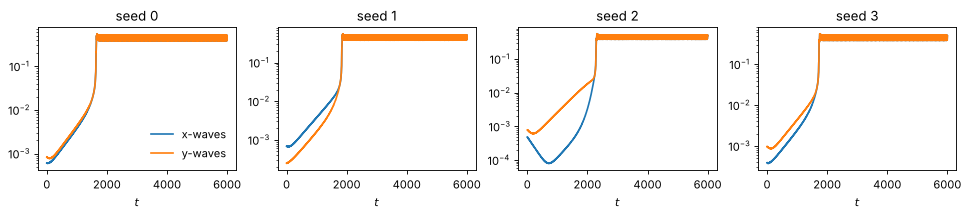

In [10]:
fig, axs = plt.subplots(1, len(runs2), figsize=(3 * len(runs2), 2.6), layout="constrained")
for ax, run, seed in zip(axs, runs2, FLICKER_SEEDS):
    amps = shell_amplitudes(run, onset2, shell_waves(k0 * k0))
    ax.semilogy(run.t, np.hypot(abs(amps[(k0, 0)]), abs(amps[(-k0, 0)])), label="x-waves")
    ax.semilogy(run.t, np.hypot(abs(amps[(0, k0)]), abs(amps[(0, -k0)])), label="y-waves")
    ax.set(title=f"seed {seed}", xlabel="$t$")
axs[0].legend(frameon=False)